# Module 3 — Task 1: Exploratory analysis of fraud

**Business problem (brief, verbatim):**
> NovaFin processes thousands of transactions every day. Management wants to identify suspicious transactions while minimizing unnecessary investigation.

**Task 1 (brief, verbatim):**
> **Task 1 — Exploratory analysis.** Investigate: Fraud rate · Fraud by transaction type · Fraud by amount · Fraud by location · Fraud by customer behaviour

**Where this task sits:** **Data and what drives fraud (this task)** → supervised fraud model (Task 2) → anomaly detection with Isolation Forest (Task 3) → the cost-based threshold (Task 4).

**What this notebook answers:** for every column in the file, does fraud differ across its values, by how much, and is that difference real or chance? Every column is analysed the same way, so a statement such as "city doesn't matter" rests on evidence, not opinion.

| Step | What it does |
| --- | --- |
| 0 | Setup |
| 1 | Know the data: quality, size, and how the columns behave |
| 2 | Fraud rate: overall, in ₹, and month by month |
| 3 | Fraud by transaction type |
| 4 | Fraud by amount |
| 5 | Fraud by location |
| 6 | Fraud by merchant category |
| 7 | Fraud by customer behaviour |
| 8 | Fraud by time of day and day of week |
| 9 | Device and customer history |
| 10 | The evidence table: every column on the same yardsticks |
| 11 | Board view in ₹ |
| 12 | What the results say |
| 13 | Save the outputs |

**The same yardsticks for every column (decision M3-10):**

| Measure | What it asks | Line |
| --- | --- | --- |
| Fraud rate per group, with a 95% Wilson range | How often is a transaction in this group fraud, and how sure are we? | — |
| Significance test (chi-square across groups; number columns across their tenths) | Is the difference between groups bigger than chance? | p below 0.05 ÷ number of tests (Bonferroni) |
| Single-column ROC-AUC | Ranking transactions by this column alone, how well does it separate fraud? 0.5 = coin flip, 1 = perfect | 0.60 |

**Verdict:** **Strong** = passes both lines · **Weak** = significant but ROC-AUC below 0.60 · **Not informative** = not significant after the adjustment. The verdicts describe each column on its own; which inputs the Task 2 models use is decided in Task 2.

**Decisions used** (in `docs/decisions.md`): M3-06 layout · M3-07 customer behaviour and derived columns · M3-08 how each "fraud by" is shown · M3-09 all 30,000 rows, description only · M3-10 the evidence rule and the tests for ID columns.

## 0. Setup

Works locally and in Google Colab.
- **Colab:** upload the whole unzipped project folder (any name) to Google Drive; the cell below finds it. Then run all cells.
- Runs in under a minute.

In [1]:
import os
import sys
import json
import warnings
from pathlib import Path

# ---- Find the project folder: any folder name works, on your computer or in Google Colab ----
# The project folder is the one holding run_novafin.ipynb and data/.
IN_COLAB = "google.colab" in sys.modules
is_project = lambda p: (p / "run_novafin.ipynb").exists() and (p / "data").is_dir()
places = [p for p in [Path.cwd(), *Path.cwd().parents] if is_project(p)]
if IN_COLAB and not places:                                 # Colab starts outside the project: look in /content, then in Google Drive
    for base in [Path("/content"), Path("/content/drive/MyDrive")]:
        if "drive" in base.parts:
            from google.colab import drive
            drive.mount("/content/drive")                   # asks for access to your Google Drive
        for depth in ["", "*/", "*/*/", "*/*/*/"]:
            places += [f.parent for f in sorted(base.glob(depth + "run_novafin.ipynb")) if is_project(f.parent)]
        if places:
            break
if not places:
    raise FileNotFoundError("Project folder not found: unzip the whole project and keep run_novafin.ipynb, data/ and the module folders together (see HOW_TO_RUN.md).")
PROJECT_ROOT = places[0]

MODULE_DIR = PROJECT_ROOT / "module_03_fraud_detection"
OUT_DIR = MODULE_DIR / "outputs" / "task1"            # tables, charts, key numbers
OUT_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(MODULE_DIR / "helpers"))       # make the Module 3 helpers importable

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

# ---- Libraries ---------------------------------------------------------------------------
import numpy as np                    # maths on arrays
import pandas as pd                   # tables
import matplotlib.pyplot as plt       # charts
from scipy import stats               # chi-square tests
from sklearn.metrics import roc_auc_score                       # single-column ROC-AUC
from statsmodels.stats.proportion import proportion_confint, proportions_ztest
import statsmodels.api as sm          # two-input logistic check in step 7

# ---- Module 3 helpers --------------------------------------------------------------------
from m03_data import load_transactions, add_features, data_report, BRIEF_COLUMNS
from m03_style import apply_style, SURFACE, INK, INK_2, GRID, BLUE, ORANGE, AQUA, FRAUD, NORMAL
apply_style()
plt.close("all")                      # start clean when run from the module runner

SEED = 42                             # one fixed random seed everywhere (project decision P-06)
LAKH, CRORE = 1e5, 1e7                # 1 lakh = ₹1,00,000; 1 crore = ₹1,00,00,000
AUC_LINE = 0.60                       # decision M3-10: single-column ROC-AUC needed for "Strong"
ALPHA = 0.05                          # significance level before the Bonferroni adjustment
pd.set_option("display.width", 200, "display.max_columns", 30)


def save_table(table: pd.DataFrame, name: str, keep_index: bool = False) -> None:
    """Save a table to outputs/task1/<name>.csv."""
    table.to_csv(OUT_DIR / f"{name}.csv", index=keep_index)


def save_chart(fig, name: str) -> None:
    """Save a chart to outputs/task1/<name>.png at print quality."""
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


print("Project folder found")
print("Outputs go to: ", OUT_DIR.relative_to(PROJECT_ROOT).as_posix())

Project folder found
Outputs go to:  module_03_fraud_detection/outputs/task1


## 1. Know the data

**Checks:** columns present, missing values, duplicates, impossible values (e.g. negative amounts).

**The file has three columns the brief doesn't list:** Transaction_ID (one per row), Customer_ID (who made it) and Timestamp (when). They let us check the history columns in step 9.

**How the "customer" columns behave.** Historical_Avg_Transaction, Account_Age_Months and Transaction_Frequency sound like fixed facts about a customer. If they were, they would be the same on every transaction of that customer. This step checks.

In [2]:
tx = add_features(load_transactions())        # 30,000 rows in time order, plus the derived columns (M3-07)
FRAUD_RATE = tx.Fraud_Flag.mean()

report = data_report(tx)
for k, v in report.items():
    print(f"{k:>26}: {v}")

# Impossible values: none of these may be zero or negative.
for col in ["Amount", "Historical_Avg_Transaction", "Account_Age_Months", "Transaction_Frequency"]:
    print(f"{col:>26}: min {tx[col].min():,.2f}, max {tx[col].max():,.2f}, values ≤ 0: {(tx[col] <= 0).sum()}")
assert report["missing_values"] == 0 and report["duplicate_transaction_ids"] == 0

# Volume: transactions per day.
days = (tx.Timestamp.max() - tx.Timestamp.min()).days + 1
print(f"\n{len(tx):,} transactions over {days} days = {len(tx) / days:.0f} a day "
      "(the brief says 'thousands every day': this file is a sample)")

                      rows: 30000
            missing_values: 0
 duplicate_transaction_ids: 0
                time_range: ('2025-01-01', '2026-08-31')
                 customers: 2500
                   devices: 1500
                fraud_rate: 0.0228
               fraud_count: 684
         fraud_value_crore: 2.01
         transaction_types: {'Payment': 16515, 'Withdrawal': 7524, 'Transfer': 5961}
                    cities: 7
                    Amount: min 147.96, max 434,340.19, values ≤ 0: 0
Historical_Avg_Transaction: min 355.22, max 80,161.54, values ≤ 0: 0
        Account_Age_Months: min 3.00, max 179.00, values ≤ 0: 0
     Transaction_Frequency: min 1.00, max 27.00, values ≤ 0: 0

30,000 transactions over 608 days = 49 a day (the brief says 'thousands every day': this file is a sample)


In [3]:
# Do the 'customer' columns stay the same across a customer's transactions?
per_customer = pd.DataFrame({
    "Share of customers whose value changes between their transactions":
        {c: (tx.groupby("Customer_ID")[c].nunique() > 1).mean()
         for c in ["Historical_Avg_Transaction", "Account_Age_Months", "Transaction_Frequency",
                   "Location", "Device_ID"]}})
per_customer["Distinct values per customer (median)"] = [
    tx.groupby("Customer_ID")[c].nunique().median() for c in per_customer.index]
per_customer["Transactions per customer (median)"] = tx.groupby("Customer_ID").size().median()

devices = tx.groupby("Device_ID").Customer_ID.nunique()
print(f"Devices: {tx.Device_ID.nunique():,}; customers per device: median {devices.median():.0f}, "
      f"devices used by more than one customer: {(devices > 1).mean():.0%}")
per_customer.style.format({per_customer.columns[0]: "{:.0%}", per_customer.columns[1]: "{:.0f}",
                           per_customer.columns[2]: "{:.0f}"})

Devices: 1,500; customers per device: median 20, devices used by more than one customer: 100%


,Share of customers whose value changes between their transactions,Distinct values per customer (median),Transactions per customer (median)
Historical_Avg_Transaction,100%,12,12
Account_Age_Months,100%,11,12
Transaction_Frequency,100%,7,12
Location,100%,6,12
Device_ID,100%,12,12


## 2. Fraud rate: overall, in ₹, and month by month

```text
Fraud rate            = fraud transactions ÷ all transactions
Fraud rate by money   = ₹ in fraud transactions ÷ ₹ in all transactions
95% Wilson range      = the range the true rate is likely to sit in, given how many transactions we have
```

**Month by month** matters for Task 2: if fraud were rising or falling over time, a model trained on early months might not suit later ones.

In [4]:
def wilson(k, n):
    """95% Wilson range for k frauds out of n transactions (works well even for small groups)."""
    lo, hi = proportion_confint(k, n, alpha=0.05, method="wilson")
    return lo, hi


fraud = tx.Fraud_Flag == 1
lo, hi = wilson(fraud.sum(), len(tx))
overall = pd.Series({
    "Transactions": len(tx), "Frauds": int(fraud.sum()),
    "Fraud rate": FRAUD_RATE, "95% low": lo, "95% high": hi,
    "₹ in all transactions (crore)": tx.Amount.sum() / CRORE,
    "₹ in fraud transactions (crore)": tx.Amount[fraud].sum() / CRORE,
    "Fraud rate by money": tx.Amount[fraud].sum() / tx.Amount.sum(),
    "Average fraud (₹)": tx.Amount[fraud].mean(), "Average normal transaction (₹)": tx.Amount[~fraud].mean(),
    "Median fraud (₹)": tx.Amount[fraud].median(), "Median normal transaction (₹)": tx.Amount[~fraud].median()})
print(overall.to_string(float_format=lambda v: f"{v:,.4f}" if abs(v) < 1 else f"{v:,.2f}"))

Transactions                      30,000.00
Frauds                               684.00
Fraud rate                           0.0228
95% low                              0.0212
95% high                             0.0246
₹ in all transactions (crore)         32.28
₹ in fraud transactions (crore)        2.01
Fraud rate by money                  0.0622
Average fraud (₹)                 29,379.68
Average normal transaction (₹)    10,326.79
Median fraud (₹)                  26,437.99
Median normal transaction (₹)      6,411.09


Months differ? chi-square p = 0.65;  steady rise or fall? correlation +0.04, p = 0.87


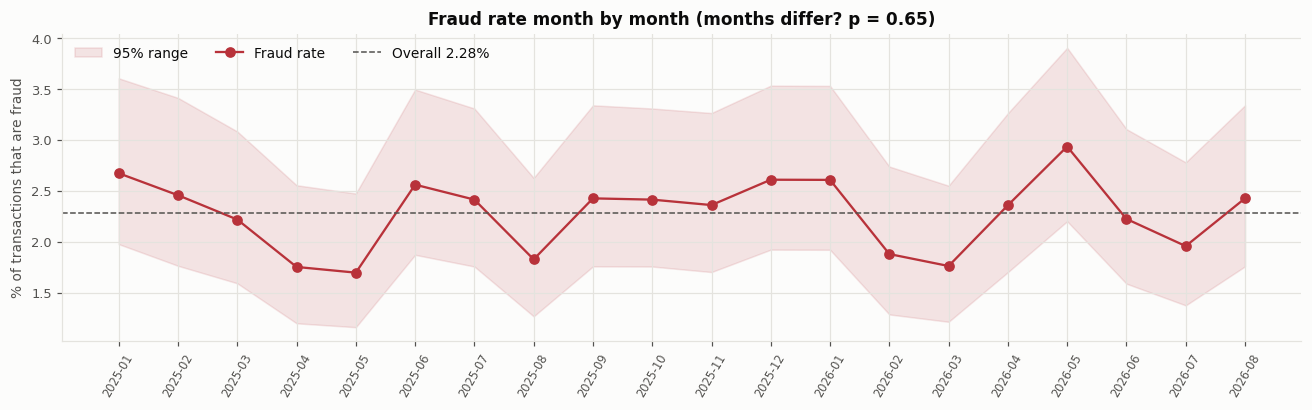

In [5]:
# Month by month: is the fraud rate stable over time?
tx["Month"] = tx.Timestamp.dt.to_period("M").astype(str)
monthly = tx.groupby("Month").agg(Transactions=("Fraud_Flag", "size"), Frauds=("Fraud_Flag", "sum"))
monthly["Fraud rate"] = monthly.Frauds / monthly.Transactions
monthly[["95% low", "95% high"]] = np.array([wilson(k, n) for k, n in zip(monthly.Frauds, monthly.Transactions)])
chi2_m, p_month, dof_m, _ = stats.chi2_contingency(pd.crosstab(tx.Month, tx.Fraud_Flag))
trend_r, p_month_trend = stats.pearsonr(np.arange(len(monthly)), monthly["Fraud rate"])
print(f"Months differ? chi-square p = {p_month:.2f};  steady rise or fall? correlation {trend_r:+.2f}, p = {p_month_trend:.2f}")

fig, ax = plt.subplots(figsize=(12, 3.8))
x = np.arange(len(monthly))
ax.fill_between(x, monthly["95% low"] * 100, monthly["95% high"] * 100, color=FRAUD, alpha=0.12, label="95% range")
ax.plot(x, monthly["Fraud rate"] * 100, "o-", color=FRAUD, label="Fraud rate")
ax.axhline(FRAUD_RATE * 100, color=INK_2, ls="--", lw=1, label=f"Overall {FRAUD_RATE:.2%}")
ax.set_xticks(x, monthly.index, rotation=60, fontsize=7.5); ax.set_ylabel("% of transactions that are fraud")
ax.set_title(f"Fraud rate month by month (months differ? p = {p_month:.2f})"); ax.legend(frameon=False, ncol=3)
fig.tight_layout(); save_chart(fig, "01_fraud_rate_by_month"); plt.show()

### The tools used for every column

```text
Fraud rate in a group      = frauds in the group ÷ transactions in the group
Chi-square test            = do the groups' fraud rates differ by more than chance?  (p < line → yes)
Cramér's V                 = size of the difference, 0 (none) to 1 (complete)
Single-column ROC-AUC      = the chance that a random fraud ranks above a random normal transaction
                             when transactions are ranked by this column alone
                             (number columns: ranked by the value, whichever direction separates;
                              label columns: ranked by each group's fraud rate)
```

The label-column ROC-AUC uses each group's own fraud rate, so it slightly flatters columns with many groups. That makes it a generous test: a column that fails it is clearly weak.

In [6]:
EVIDENCE = []                         # one row per column tested; becomes the evidence table in step 10


def fraud_by(t: pd.DataFrame, groups: pd.Series) -> pd.DataFrame:
    """Fraud rate (with 95% range), counts and ₹ for each group."""
    g = t.groupby(groups, observed=True)
    tbl = pd.DataFrame({"Transactions": g.size(), "Frauds": g.Fraud_Flag.sum(),
                        "₹ in fraud (lakh)": g.apply(lambda s: s.Amount[s.Fraud_Flag == 1].sum()) / LAKH,
                        "Average amount (₹)": g.Amount.mean()})
    tbl["Fraud rate"] = tbl.Frauds / tbl.Transactions
    rng_ = np.array([wilson(k, n) for k, n in zip(tbl.Frauds, tbl.Transactions)])
    tbl["95% low"], tbl["95% high"] = rng_[:, 0], rng_[:, 1]
    tbl["Share of frauds"] = tbl.Frauds / tbl.Frauds.sum()
    tbl["Share of fraud ₹"] = tbl["₹ in fraud (lakh)"] / tbl["₹ in fraud (lakh)"].sum()
    return tbl[["Transactions", "Frauds", "Fraud rate", "95% low", "95% high", "Share of frauds",
                "₹ in fraud (lakh)", "Share of fraud ₹", "Average amount (₹)"]]


def test_column(name: str, groups: pd.Series, score: pd.Series | None = None, kind: str = "label") -> dict:
    """Chi-square across groups, Cramér's V and single-column ROC-AUC; adds a row to EVIDENCE.

    groups : the group of each transaction (a label, or the tenth for number columns)
    score  : number column used for the ROC-AUC (None = use each group's fraud rate)
    """
    y = tx.Fraud_Flag.loc[groups.index]                   # outcomes of the rows being tested
    table = pd.crosstab(groups, y)
    chi2, p, dof, _ = stats.chi2_contingency(table)
    v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    s = score if score is not None else groups.map(y.groupby(groups, observed=True).mean()).astype(float)
    auc = roc_auc_score(y, s)
    direction = "higher → more fraud" if auc >= 0.5 else "lower → more fraud"
    rates = table[1] / table.sum(axis=1)
    row = {"Column": name, "Kind": kind, "Groups": len(table), "Test": "Chi-square", "p": p, "Cramér's V": v,
           "ROC-AUC": max(auc, 1 - auc), "Direction": direction if score is not None else "by group",
           "Lowest group rate": rates.min(), "Highest group rate": rates.max()}
    EVIDENCE.append(row)
    return row


def plot_rates(ax, tbl: pd.DataFrame, title: str, colour=FRAUD, rotate: int = 0) -> None:
    """Fraud rate per group with its 95% range, against the overall rate."""
    x = np.arange(len(tbl))
    r = tbl["Fraud rate"] * 100
    ax.bar(x, r, color=colour, alpha=0.85)
    ax.errorbar(x, r, yerr=[r - tbl["95% low"] * 100, tbl["95% high"] * 100 - r], fmt="none", ecolor=INK, capsize=3, lw=1)
    ax.axhline(FRAUD_RATE * 100, color=INK_2, ls="--", lw=1)
    ax.set_xticks(x, [str(i) for i in tbl.index], rotation=rotate, fontsize=8, ha="right" if rotate else "center")
    ax.set_ylabel("% fraud"); ax.set_title(title, fontsize=10)


def show(tbl: pd.DataFrame):
    """Display a fraud_by table with readable formats."""
    return tbl.style.format({"Transactions": "{:,.0f}", "Frauds": "{:,.0f}", "Fraud rate": "{:.2%}",
                             "95% low": "{:.2%}", "95% high": "{:.2%}", "Share of frauds": "{:.1%}",
                             "₹ in fraud (lakh)": "₹{:,.1f}", "Share of fraud ₹": "{:.1%}",
                             "Average amount (₹)": "₹{:,.0f}"})


def tenths(col: str) -> pd.Series:
    """Tenth of a number column (10 equal-sized groups), labelled with its ₹ or value range."""
    return pd.qcut(tx[col], 10, duplicates="drop")


print("Tools ready.")

Tools ready.


## 3. Fraud by transaction type (brief item)

In [7]:
t_type = fraud_by(tx, tx.Transaction_Type)
r = test_column("Transaction_Type", tx.Transaction_Type)
# Which type stands out? Each type against all the others (two-proportion z test).
for typ in t_type.index:
    m = tx.Transaction_Type == typ
    z, p_one = proportions_ztest([tx.Fraud_Flag[m].sum(), tx.Fraud_Flag[~m].sum()], [m.sum(), (~m).sum()])
    print(f"{typ:<11} {t_type.loc[typ, 'Fraud rate']:.2%} vs the rest {tx.Fraud_Flag[~m].mean():.2%}: p = {p_one:.4f}")
print(f"Types differ? chi-square p = {r['p']:.4f};  ROC-AUC {r['ROC-AUC']:.3f}")
show(t_type)

Payment     2.09% vs the rest 2.51%: p = 0.0142
Transfer    2.97% vs the rest 2.11%: p = 0.0001
Withdrawal  2.15% vs the rest 2.32%: p = 0.3943
Types differ? chi-square p = 0.0003;  ROC-AUC 0.533


Notebook cell, line 8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "₹ in fraud (lakh)": g.apply(lambda s: s.Amount[s.Fraud_Flag == 1].sum()) / LAKH,


,Transactions,Frauds,Fraud rate,95% low,95% high,Share of frauds,₹ in fraud (lakh),Share of fraud ₹,Average amount (₹)
Transaction_Type,,,,,,,,,
Payment,"16,515",345,2.09%,1.88%,2.32%,50.4%,₹98.6,49.0%,"₹10,711"
Transfer,"5,961",177,2.97%,2.57%,3.43%,25.9%,₹52.5,26.1%,"₹10,760"
Withdrawal,"7,524",162,2.15%,1.85%,2.51%,23.7%,₹49.9,24.8%,"₹10,873"


## 4. Fraud by amount (brief item)

Amount is shown two ways:
- **in tenths** (10 equal-sized groups, smallest to largest), with the ₹ range of each;
- **as concentration:** what share of all frauds, and of the ₹ lost to fraud, sits in the largest transactions.

In [8]:
amt_tenth = tenths("Amount")
t_amt = fraud_by(tx, amt_tenth)
t_amt.index = [f"{i + 1}: ₹{iv.left:,.0f}–₹{iv.right:,.0f}" for i, iv in enumerate(t_amt.index)]
r = test_column("Amount", amt_tenth, tx.Amount, kind="number")
print(f"Tenths differ? chi-square p = {r['p']:.1e};  ROC-AUC {r['ROC-AUC']:.3f} ({r['Direction']})")

# Concentration: the largest x% of transactions hold what share of frauds and of fraud ₹?
order = tx.sort_values("Amount", ascending=False)
conc = []
for share in [0.01, 0.05, 0.10, 0.20]:
    top = order.head(int(share * len(tx)))
    conc.append({"Largest transactions": f"{share:.0%}", "From (₹)": top.Amount.min(),
                 "Fraud rate": top.Fraud_Flag.mean(), "Share of all frauds": top.Fraud_Flag.sum() / fraud.sum(),
                 "Share of fraud ₹": top.Amount[top.Fraud_Flag == 1].sum() / tx.Amount[fraud].sum()})
conc = pd.DataFrame(conc)
display(conc.style.format({"From (₹)": "₹{:,.0f}", "Fraud rate": "{:.1%}", "Share of all frauds": "{:.0%}",
                           "Share of fraud ₹": "{:.0%}"}).hide(axis="index"))
show(t_amt)

Tenths differ? chi-square p = 0.0e+00;  ROC-AUC 0.788 (higher → more fraud)


Largest transactions,From (₹),Fraud rate,Share of all frauds,Share of fraud ₹
1%,"₹67,733",13.7%,6%,21%
5%,"₹33,738",15.2%,33%,64%
10%,"₹23,331",12.7%,56%,85%
20%,"₹15,118",7.5%,66%,92%


,Transactions,Frauds,Fraud rate,95% low,95% high,Share of frauds,₹ in fraud (lakh),Share of fraud ₹,Average amount (₹)
"1: ₹148–₹1,811","3,000",18,0.60%,0.38%,0.95%,2.6%,₹0.2,0.1%,"₹1,211"
"2: ₹1,811–₹2,816","3,000",20,0.67%,0.43%,1.03%,2.9%,₹0.5,0.2%,"₹2,314"
"3: ₹2,816–₹3,862","3,000",20,0.67%,0.43%,1.03%,2.9%,₹0.6,0.3%,"₹3,339"
"4: ₹3,862–₹5,093","3,000",27,0.90%,0.62%,1.31%,3.9%,₹1.2,0.6%,"₹4,465"
"5: ₹5,093–₹6,540","3,000",27,0.90%,0.62%,1.31%,3.9%,₹1.6,0.8%,"₹5,785"
"6: ₹6,540–₹8,414","3,000",36,1.20%,0.87%,1.66%,5.3%,₹2.7,1.3%,"₹7,430"
"7: ₹8,414–₹10,962","3,000",37,1.23%,0.90%,1.70%,5.4%,₹3.6,1.8%,"₹9,628"
"8: ₹10,962–₹15,118","3,000",46,1.53%,1.15%,2.04%,6.7%,₹6.1,3.0%,"₹12,865"
"9: ₹15,118–₹23,330","3,000",73,2.43%,1.94%,3.05%,10.7%,₹13.5,6.7%,"₹18,593"
"10: ₹23,330–₹434,340","3,000",380,12.67%,11.52%,13.90%,55.6%,₹171.0,85.1%,"₹41,982"


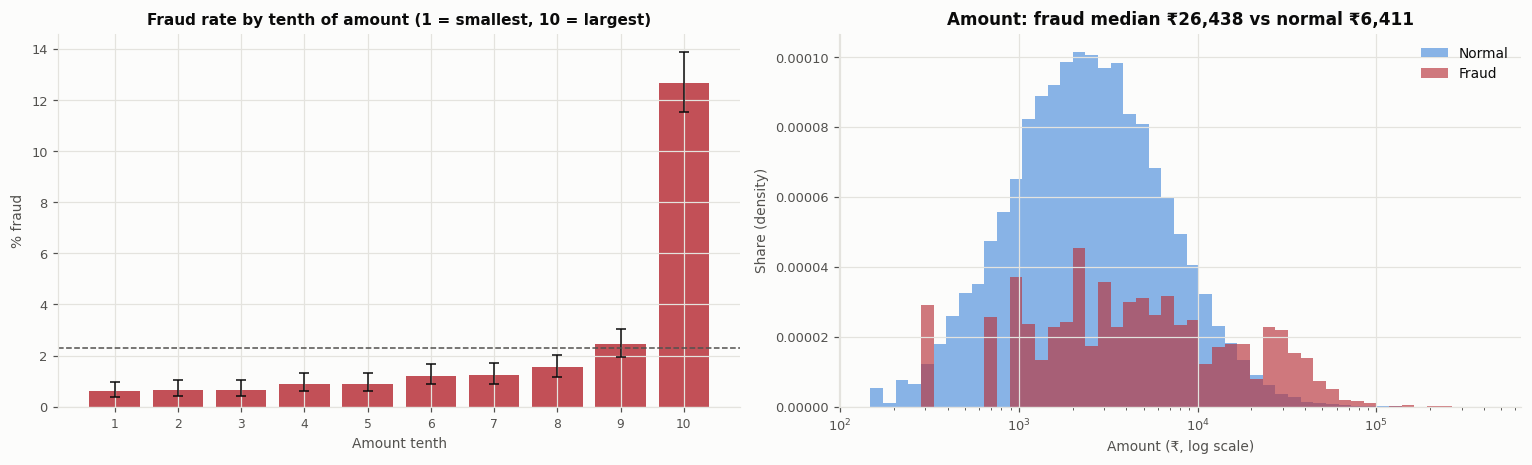

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
plot_rates(axes[0], t_amt.set_axis([str(i + 1) for i in range(len(t_amt))]),
           "Fraud rate by tenth of amount (1 = smallest, 10 = largest)")
axes[0].set_xlabel("Amount tenth")
bins = np.logspace(np.log10(tx.Amount.min()), np.log10(tx.Amount.max()), 50)
axes[1].hist(tx.Amount[~fraud], bins=bins, density=True, alpha=0.55, color=NORMAL, label="Normal")
axes[1].hist(tx.Amount[fraud], bins=bins, density=True, alpha=0.65, color=FRAUD, label="Fraud")
axes[1].set_xscale("log"); axes[1].set_xlabel("Amount (₹, log scale)"); axes[1].set_ylabel("Share (density)")
axes[1].set_title(f"Amount: fraud median ₹{tx.Amount[fraud].median():,.0f} vs normal ₹{tx.Amount[~fraud].median():,.0f}")
axes[1].legend(frameon=False)
fig.tight_layout(); save_chart(fig, "02_fraud_by_amount"); plt.show()

## 5. Fraud by location (brief item)

In [10]:
t_loc = fraud_by(tx, tx.Location).sort_values("Fraud rate", ascending=False)
r = test_column("Location", tx.Location)
print(f"Cities differ? chi-square p = {r['p']:.2f};  ROC-AUC {r['ROC-AUC']:.3f}")
show(t_loc)

Cities differ? chi-square p = 0.96;  ROC-AUC 0.513


Notebook cell, line 8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "₹ in fraud (lakh)": g.apply(lambda s: s.Amount[s.Fraud_Flag == 1].sum()) / LAKH,


,Transactions,Frauds,Fraud rate,95% low,95% high,Share of frauds,₹ in fraud (lakh),Share of fraud ₹,Average amount (₹)
Location,,,,,,,,,
Bengaluru,"4,307",105,2.44%,2.02%,2.94%,15.4%,₹30.8,15.3%,"₹10,547"
Mumbai,"4,282",103,2.41%,1.99%,2.91%,15.1%,₹35.8,17.8%,"₹11,232"
Kolkata,"4,233",99,2.34%,1.92%,2.84%,14.5%,₹26.7,13.3%,"₹10,602"
Chennai,"4,278",96,2.24%,1.84%,2.73%,14.0%,₹26.1,13.0%,"₹10,820"
Pune,"4,368",97,2.22%,1.82%,2.70%,14.2%,₹29.0,14.4%,"₹10,539"
Hyderabad,"4,292",93,2.17%,1.77%,2.65%,13.6%,₹25.3,12.6%,"₹10,769"
Delhi,"4,240",91,2.15%,1.75%,2.63%,13.3%,₹27.3,13.6%,"₹10,825"


## 6. Fraud by merchant category

Not one of the brief's five items, but it is in the file and in the brief's variable list, so it gets the same test.

In [11]:
t_merch = fraud_by(tx, tx.Merchant_Category).sort_values("Fraud rate", ascending=False)
r = test_column("Merchant_Category", tx.Merchant_Category)
print(f"Categories differ? chi-square p = {r['p']:.2f};  ROC-AUC {r['ROC-AUC']:.3f}")
show(t_merch)

Categories differ? chi-square p = 0.43;  ROC-AUC 0.526


Notebook cell, line 8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "₹ in fraud (lakh)": g.apply(lambda s: s.Amount[s.Fraud_Flag == 1].sum()) / LAKH,


,Transactions,Frauds,Fraud rate,95% low,95% high,Share of frauds,₹ in fraud (lakh),Share of fraud ₹,Average amount (₹)
Merchant_Category,,,,,,,,,
Healthcare,"4,315",108,2.50%,2.08%,3.01%,15.8%,₹30.1,15.0%,"₹10,669"
Retail,"4,309",107,2.48%,2.06%,2.99%,15.6%,₹33.6,16.7%,"₹10,797"
Investment,"4,261",103,2.42%,2.00%,2.92%,15.1%,₹35.4,17.6%,"₹11,191"
Other,"4,337",104,2.40%,1.98%,2.90%,15.2%,₹29.9,14.9%,"₹10,521"
Utilities,"4,257",93,2.18%,1.79%,2.67%,13.6%,₹26.8,13.3%,"₹10,736"
Travel,"4,178",84,2.01%,1.63%,2.48%,12.3%,₹19.6,9.8%,"₹10,757"
Online,"4,343",85,1.96%,1.59%,2.41%,12.4%,₹25.6,12.7%,"₹10,664"


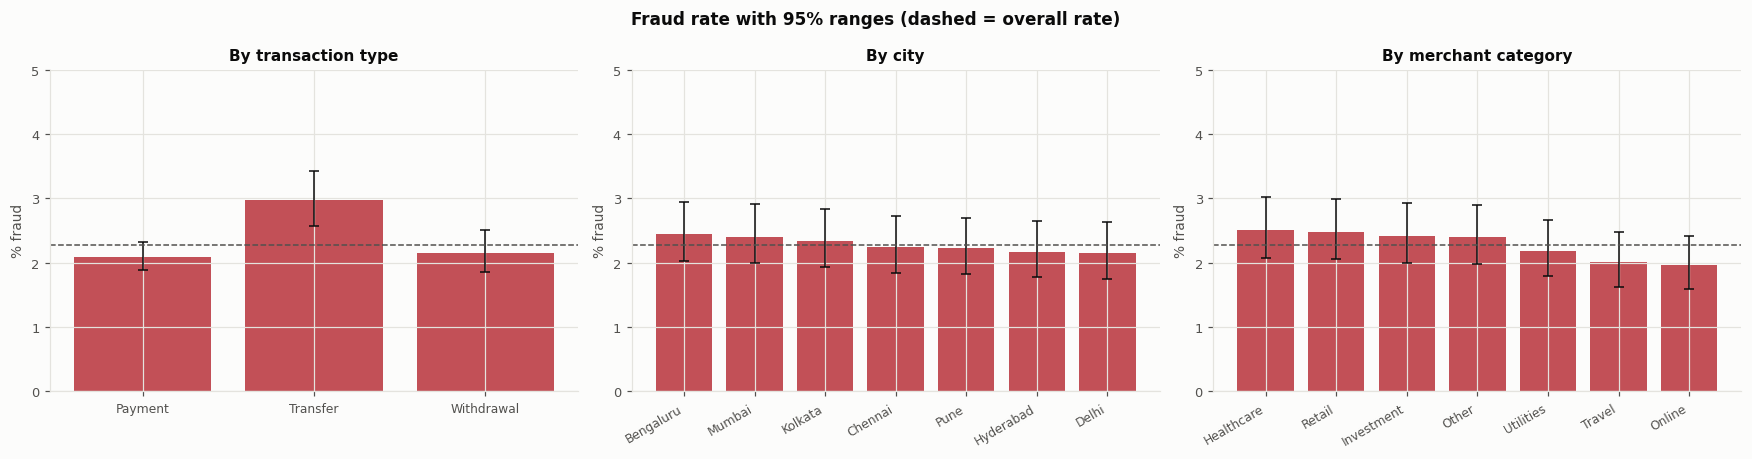

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
plot_rates(axes[0], t_type, "By transaction type")
plot_rates(axes[1], t_loc, "By city", rotate=30)
plot_rates(axes[2], t_merch, "By merchant category", rotate=30)
for ax in axes:
    ax.set_ylim(0, 5)
fig.suptitle("Fraud rate with 95% ranges (dashed = overall rate)", fontsize=11, fontweight="bold")
fig.tight_layout(); save_chart(fig, "03_fraud_by_type_city_merchant"); plt.show()

## 7. Fraud by customer behaviour (brief item; decision M3-07)

"Customer behaviour" covers the three behaviour columns in the brief, plus one derived column:

```text
Amount_Ratio = Amount ÷ Historical_Avg_Transaction      how unusual this amount is for this customer
               1 = their usual amount; 5 = five times it
```

| Column | What it describes |
| --- | --- |
| Historical_Avg_Transaction | The customer's usual transaction size |
| Amount_Ratio | This amount against the usual one |
| Account_Age_Months | How long the account has been open |
| Transaction_Frequency | How often the customer transacts |

Each is cut into tenths (Transaction_Frequency has few distinct values, so it gets fewer groups).

In [13]:
behaviour = {}
for col in ["Historical_Avg_Transaction", "Amount_Ratio", "Account_Age_Months", "Transaction_Frequency"]:
    g = tenths(col)
    tbl = fraud_by(tx, g)
    tbl.index = [f"{iv.left:,.2f}–{iv.right:,.2f}" if col == "Amount_Ratio" else f"{iv.left:,.0f}–{iv.right:,.0f}"
                 for iv in tbl.index]
    r = test_column(col, g, tx[col], kind="number")
    behaviour[col] = tbl
    print(f"{col:<28} groups {len(tbl):>2} | p = {r['p']:.1e} | ROC-AUC {r['ROC-AUC']:.3f} ({r['Direction']}) | "
          f"rate {tbl['Fraud rate'].min():.1%} → {tbl['Fraud rate'].max():.1%}")

ratio_by_flag = tx.groupby("Fraud_Flag").Amount_Ratio.median()
print(f"\nMedian Amount_Ratio: fraud {ratio_by_flag[1]:.2f}× the usual amount, normal {ratio_by_flag[0]:.2f}×")
print(f"Correlation of Amount with Amount_Ratio: {tx.Amount.corr(tx.Amount_Ratio):.2f} "
      "(how much the two strong columns overlap)")

# Why does a smaller usual amount mean more fraud?  Two-input logistic check on log scales:
# log-odds of fraud = a + b1 × ln(Amount) + b2 × ln(Historical_Avg_Transaction).
# If b2 < 0 with Amount held fixed, a smaller usual amount raises the risk for the same amount (a bigger jump).
print(f"Correlation of Amount with Historical_Avg_Transaction: {tx.Amount.corr(tx.Historical_Avg_Transaction):.2f}")
X_chk = sm.add_constant(pd.DataFrame({"ln(Amount)": np.log(tx.Amount),
                                      "ln(Historical_Avg_Transaction)": np.log(tx.Historical_Avg_Transaction)}))
chk = sm.Logit(tx.Fraud_Flag, X_chk).fit(disp=0)
print(pd.DataFrame({"weight": chk.params, "p": chk.pvalues}).round(4).to_string())
show(behaviour["Amount_Ratio"])

Historical_Avg_Transaction   groups 10 | p = 4.8e-09 | ROC-AUC 0.583 (lower → more fraud) | rate 1.1% → 3.3%
Amount_Ratio                 groups 10 | p = 2.6e-255 | ROC-AUC 0.787 (higher → more fraud) | rate 0.5% → 10.3%
Account_Age_Months           groups 10 | p = 1.6e-01 | ROC-AUC 0.519 (higher → more fraud) | rate 1.6% → 2.8%


Transaction_Frequency        groups  8 | p = 2.9e-01 | ROC-AUC 0.517 (lower → more fraud) | rate 2.0% → 2.7%

Median Amount_Ratio: fraud 5.00× the usual amount, normal 1.17×
Correlation of Amount with Amount_Ratio: 0.71 (how much the two strong columns overlap)
Correlation of Amount with Historical_Avg_Transaction: 0.00
                                 weight    p
const                          -10.7508  0.0
ln(Amount)                       1.1605  0.0
ln(Historical_Avg_Transaction)  -0.4485  0.0


,Transactions,Frauds,Fraud rate,95% low,95% high,Share of frauds,₹ in fraud (lakh),Share of fraud ₹,Average amount (₹)
0.01–0.25,"3,000",25,0.83%,0.57%,1.23%,3.7%,₹0.5,0.2%,"₹1,892"
0.25–0.42,"3,000",16,0.53%,0.33%,0.86%,2.3%,₹0.5,0.3%,"₹3,315"
0.42–0.63,"3,000",21,0.70%,0.46%,1.07%,3.1%,₹1.0,0.5%,"₹4,444"
0.63–0.88,"3,000",20,0.67%,0.43%,1.03%,2.9%,₹0.9,0.5%,"₹5,598"
0.88–1.20,"3,000",26,0.87%,0.59%,1.27%,3.8%,₹2.4,1.2%,"₹7,143"
1.20–1.62,"3,000",18,0.60%,0.38%,0.95%,2.6%,₹2.0,1.0%,"₹8,693"
1.62–2.26,"3,000",33,1.10%,0.78%,1.54%,4.8%,₹4.3,2.1%,"₹10,465"
2.26–3.33,"3,000",57,1.90%,1.47%,2.45%,8.3%,₹10.3,5.1%,"₹13,299"
3.33–5.64,"3,000",159,5.30%,4.55%,6.16%,23.2%,₹40.8,20.3%,"₹17,898"
5.64–324.12,"3,000",309,10.30%,9.26%,11.44%,45.2%,₹138.3,68.8%,"₹34,865"


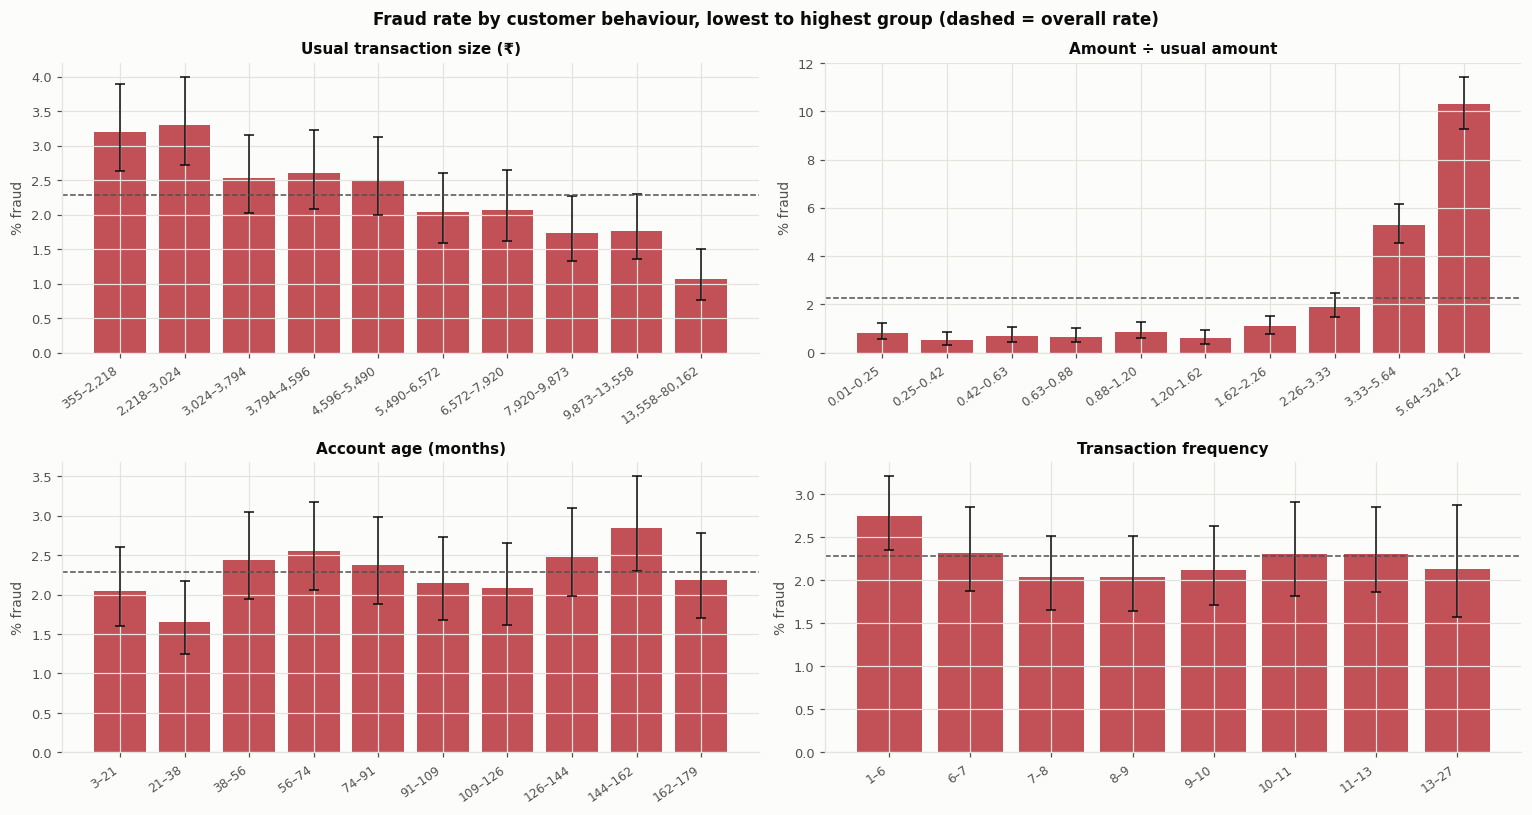

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7.5))
titles = {"Historical_Avg_Transaction": "Usual transaction size (₹)", "Amount_Ratio": "Amount ÷ usual amount",
          "Account_Age_Months": "Account age (months)", "Transaction_Frequency": "Transaction frequency"}
for ax, (col, tbl) in zip(axes.ravel(), behaviour.items()):
    plot_rates(ax, tbl, titles[col], rotate=35)
fig.suptitle("Fraud rate by customer behaviour, lowest to highest group (dashed = overall rate)", fontsize=11,
             fontweight="bold")
fig.tight_layout(); save_chart(fig, "04_fraud_by_customer_behaviour"); plt.show()

## 8. Fraud by time of day and day of week

From Timestamp: the hour (grouped into six 4-hour blocks) and the day of the week.

Notebook cell, line 8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "₹ in fraud (lakh)": g.apply(lambda s: s.Amount[s.Fraud_Flag == 1].sum()) / LAKH,


Hours differ? p = 0.33, ROC-AUC 0.526;  days differ? p = 0.82, ROC-AUC 0.518


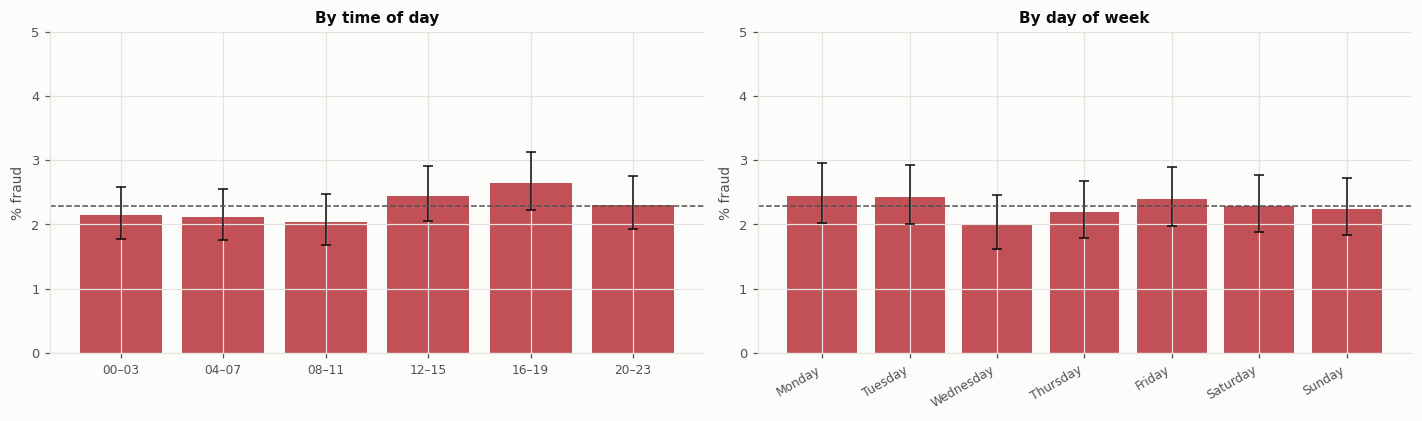

In [15]:
hour_block = pd.cut(tx.Hour, [-1, 3, 7, 11, 15, 19, 23], labels=["00–03", "04–07", "08–11", "12–15", "16–19", "20–23"])
t_hour = fraud_by(tx, hour_block)
r1 = test_column("Hour of day", hour_block)
t_day = fraud_by(tx, tx.Weekday)
r2 = test_column("Day of week", tx.Weekday)
print(f"Hours differ? p = {r1['p']:.2f}, ROC-AUC {r1['ROC-AUC']:.3f};  days differ? p = {r2['p']:.2f}, ROC-AUC {r2['ROC-AUC']:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.9))
plot_rates(axes[0], t_hour, "By time of day")
plot_rates(axes[1], t_day, "By day of week", rotate=30)
for ax in axes:
    ax.set_ylim(0, 5)
fig.tight_layout(); save_chart(fig, "05_fraud_by_time"); plt.show()

## 9. Device and customer history

Device_ID and Customer_ID are **identifiers**: their numbers have no meaning as a scale, so cutting them into tenths would test nothing real (decision M3-10). Instead we test what could matter:

| Question | Test |
| --- | --- |
| Does the customer's device change since their previous transaction? Is that riskier? | Fraud rate with vs without a change; chi-square; ROC-AUC (each customer's first transaction left out: nothing to compare with) |
| Does the customer's city change since their previous transaction? | Same |
| Do frauds cluster on certain devices (or customers) more than chance would give? | Dispersion test: compares each device's fraud count with what its number of transactions would predict |
| Is a transaction riskier if its device (or customer) had a fraud **earlier**? | Fraud rate with vs without an earlier fraud; uses only earlier transactions |

```text
Dispersion test: Σ over devices of (frauds − expected)² ÷ (expected × (1 − fraud rate)),  expected = transactions × overall fraud rate
                 compared with a chi-square with (devices − 1) degrees of freedom; p < line → frauds cluster
```

In [16]:
# (a) Device and location change since the customer's previous transaction (from add_features).
#     A customer's first transaction has nothing to compare with, so it is left out of this test.
has_prev = tx.groupby("Customer_ID").cumcount() > 0
print(f"Transactions with an earlier one from the same customer: {has_prev.sum():,} of {len(tx):,}")
for col, label in [("Device_Change", "Device change"), ("Location_Change", "Location change")]:
    sub = tx[has_prev]
    groups = sub[col].map({0: "No change", 1: "Changed"})
    tbl = fraud_by(sub, groups)
    r = test_column(label, groups)
    print(f"{label}: share changed {sub[col].mean():.2%} | rates {tbl['Fraud rate'].round(4).to_dict()} | "
          f"p = {r['p']:.2f} | ROC-AUC {r['ROC-AUC']:.3f}")


# (b) Do frauds cluster on the same device / customer?
def dispersion(id_col: str, label: str) -> None:
    g = tx.groupby(id_col).Fraud_Flag.agg(["size", "sum"])
    expected = g["size"] * FRAUD_RATE
    chi2 = ((g["sum"] - expected) ** 2 / (expected * (1 - FRAUD_RATE))).sum()
    p = stats.chi2.sf(chi2, len(g) - 1)
    EVIDENCE.append({"Column": label, "Kind": "identifier", "Groups": len(g), "Test": "Dispersion", "p": p,
                     "Cramér's V": np.nan, "ROC-AUC": np.nan, "Direction": "—",
                     "Lowest group rate": np.nan, "Highest group rate": np.nan})
    print(f"{label}: {len(g):,} {id_col}s, frauds per {id_col}: {g['sum'].value_counts().sort_index().to_dict()} | p = {p:.3f}")


# (c) Is a transaction riskier if its device / customer had a fraud earlier? (earlier rows only)
def earlier_fraud(id_col: str, label: str) -> None:
    prior = tx.groupby(id_col).Fraud_Flag.transform(lambda s: s.shift().fillna(0).cumsum()) > 0
    groups = prior.map({False: "No earlier fraud", True: "Earlier fraud"})
    tbl = fraud_by(tx, groups)
    r = test_column(label, groups)
    r["Kind"] = "identifier"
    print(f"{label}: rates {tbl['Fraud rate'].round(4).to_dict()} | p = {r['p']:.2f} | ROC-AUC {r['ROC-AUC']:.3f}")


dispersion("Device_ID", "Frauds cluster on devices")
earlier_fraud("Device_ID", "Device had an earlier fraud")
dispersion("Customer_ID", "Frauds cluster on customers")
earlier_fraud("Customer_ID", "Customer had an earlier fraud")

Transactions with an earlier one from the same customer: 27,500 of 30,000
Device change: share changed 99.95% | rates {'Changed': 0.0227, 'No change': 0.0714} | p = 0.74 | ROC-AUC 0.501
Location change: share changed 85.68% | rates {'Changed': 0.0225, 'No change': 0.0244} | p = 0.49 | ROC-AUC 0.505
Frauds cluster on devices: 1,500 Device_IDs, frauds per Device_ID: {0: 961, 1: 412, 2: 110, 3: 16, 4: 1} | p = 0.046


Device had an earlier fraud: rates {'Earlier fraud': 0.0247, 'No earlier fraud': 0.0223} | p = 0.31 | ROC-AUC 0.508
Frauds cluster on customers: 2,500 Customer_IDs, frauds per Customer_ID: {0: 1898, 1: 527, 2: 68, 3: 7} | p = 0.611


Customer had an earlier fraud: rates {'Earlier fraud': 0.0218, 'No earlier fraud': 0.0229} | p = 0.71 | ROC-AUC 0.503


## 10. The evidence table: every column on the same yardsticks (decision M3-10)

```text
Bonferroni line = 0.05 ÷ number of tests      (guards against 1-in-20 chance findings across many tests)
Strong          = p below the line  AND  single-column ROC-AUC ≥ 0.60
Weak            = p below the line, ROC-AUC below 0.60 (real but too small to separate fraud on its own)
Not informative = p above the line
```

Two checks on the rule itself:
- **Does the 0.60 line decide anything?** We show the gap between the weakest "Strong" and the strongest other column.
- **Does the Bonferroni adjustment decide anything?** We show which verdicts would change at a plain 0.05.

In [17]:
ev = pd.DataFrame(EVIDENCE)
N_TESTS = len(ev)
P_LINE = ALPHA / N_TESTS


def verdict(p, auc, line):
    if p >= line:
        return "Not informative"
    return "Strong" if (not np.isnan(auc) and auc >= AUC_LINE) else "Weak"


ev["Verdict"] = [verdict(p, a, P_LINE) for p, a in zip(ev.p, ev["ROC-AUC"])]
ev["Verdict at plain 0.05"] = [verdict(p, a, ALPHA) for p, a in zip(ev.p, ev["ROC-AUC"])]
order_ = {"Strong": 0, "Weak": 1, "Not informative": 2}
ev = ev.sort_values(["Verdict", "ROC-AUC"], key=lambda s: s.map(order_) if s.name == "Verdict" else -s.fillna(0))
save_table(ev.round(5), "FINAL_M3_T1_fraud_evidence")

strong = ev[ev.Verdict == "Strong"]
others = ev[ev.Verdict != "Strong"]
gap = (strong["ROC-AUC"].min(), others["ROC-AUC"].max())
changed = ev[ev.Verdict != ev["Verdict at plain 0.05"]]
print(f"{N_TESTS} tests; Bonferroni line p < {P_LINE:.4f}")
print(f"0.60 line: weakest Strong ROC-AUC {gap[0]:.3f}, strongest other {gap[1]:.3f} → "
      f"any line between them gives the same verdicts")
print("Verdicts that change at a plain 0.05:",
      ", ".join(f"{c} ({a} → {b})" for c, a, b in zip(changed.Column, changed.Verdict, changed["Verdict at plain 0.05"]))
      or "none")
ev.style.format({"p": "{:.1e}", "Cramér's V": "{:.3f}", "ROC-AUC": "{:.3f}", "Lowest group rate": "{:.2%}",
                 "Highest group rate": "{:.2%}"}, na_rep="—").hide(axis="index")

16 tests; Bonferroni line p < 0.0031
0.60 line: weakest Strong ROC-AUC 0.787, strongest other 0.583 → any line between them gives the same verdicts
Verdicts that change at a plain 0.05: Frauds cluster on devices (Not informative → Weak)


Column,Kind,Groups,Test,p,Cramér's V,ROC-AUC,Direction,Lowest group rate,Highest group rate,Verdict,Verdict at plain 0.05
Amount,number,10,Chi-square,0.0e+00,0.235,0.788,higher → more fraud,0.60%,12.67%,Strong,Strong
Amount_Ratio,number,10,Chi-square,2.6e-255,0.201,0.787,higher → more fraud,0.53%,10.30%,Strong,Strong
Historical_Avg_Transaction,number,10,Chi-square,4.8e-09,0.044,0.583,lower → more fraud,1.07%,3.30%,Weak,Weak
Transaction_Type,label,3,Chi-square,3.4e-04,0.023,0.533,by group,2.09%,2.97%,Weak,Weak
Merchant_Category,label,7,Chi-square,4.3e-01,0.014,0.526,by group,1.96%,2.50%,Not informative,Not informative
Hour of day,label,6,Chi-square,3.3e-01,0.014,0.526,by group,2.04%,2.64%,Not informative,Not informative
Account_Age_Months,number,10,Chi-square,1.6e-01,0.021,0.519,higher → more fraud,1.65%,2.84%,Not informative,Not informative
Day of week,label,7,Chi-square,8.2e-01,0.010,0.518,by group,2.00%,2.45%,Not informative,Not informative
Transaction_Frequency,number,8,Chi-square,2.9e-01,0.017,0.517,lower → more fraud,2.03%,2.75%,Not informative,Not informative
Location,label,7,Chi-square,9.6e-01,0.007,0.513,by group,2.15%,2.44%,Not informative,Not informative


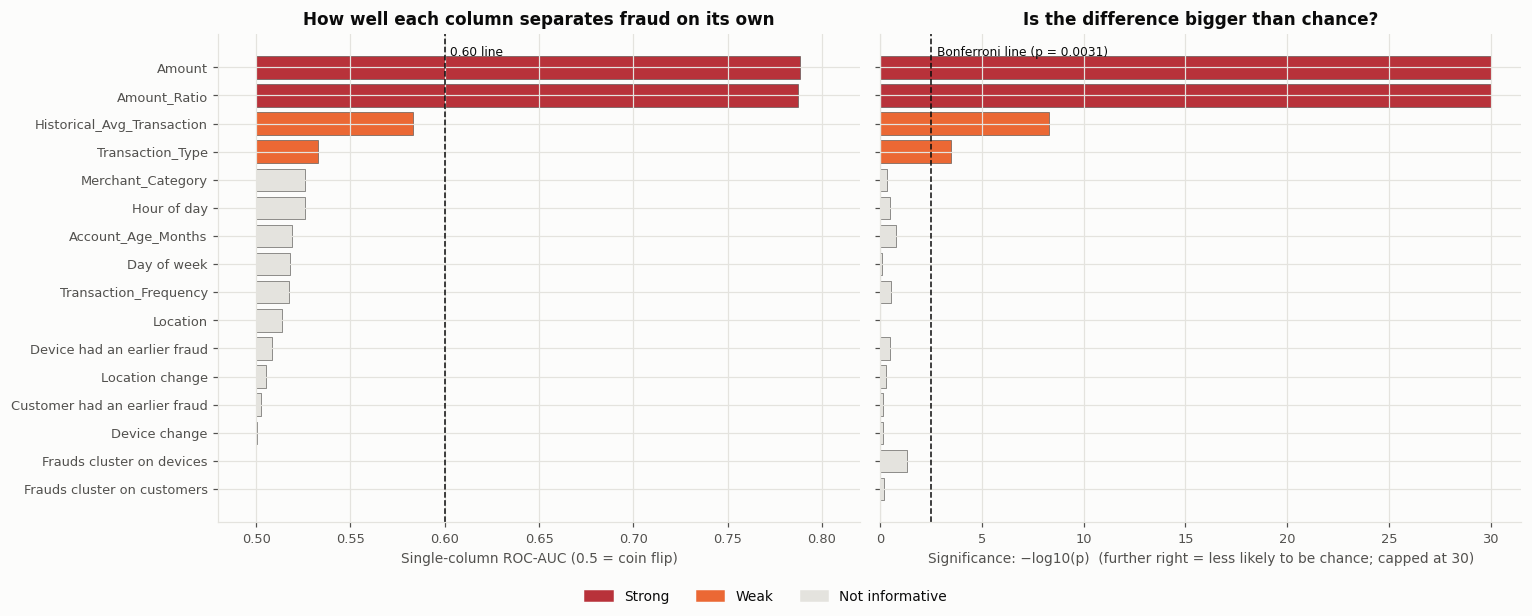

In [18]:
# Chart: every column's ROC-AUC (left) and significance (right), coloured by verdict.
VC = {"Strong": FRAUD, "Weak": ORANGE, "Not informative": GRID}
fig, axes = plt.subplots(1, 2, figsize=(14, 5.6), sharey=True)
y_ = np.arange(len(ev))[::-1]
axes[0].barh(y_, ev["ROC-AUC"].fillna(0.5) - 0.5, left=0.5, color=[VC[v] for v in ev.Verdict], edgecolor=INK_2, lw=0.4)
axes[0].axvline(AUC_LINE, color=INK, ls="--", lw=1); axes[0].text(AUC_LINE + 0.003, len(ev) - 0.6, "0.60 line", fontsize=8)
axes[0].set_xlim(0.48, 0.82); axes[0].set_xlabel("Single-column ROC-AUC (0.5 = coin flip)")
axes[0].set_yticks(y_, ev.Column, fontsize=8.5); axes[0].set_title("How well each column separates fraud on its own")
logp = -np.log10(ev.p.clip(lower=1e-30))
axes[1].barh(y_, logp, color=[VC[v] for v in ev.Verdict], edgecolor=INK_2, lw=0.4)
axes[1].axvline(-np.log10(P_LINE), color=INK, ls="--", lw=1)
axes[1].text(-np.log10(P_LINE) + 0.3, len(ev) - 0.6, f"Bonferroni line (p = {P_LINE:.4f})", fontsize=8)
axes[1].set_xlabel("Significance: −log10(p)  (further right = less likely to be chance; capped at 30)")
axes[1].set_title("Is the difference bigger than chance?")
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=c, label=k) for k, c in VC.items()], loc="lower center", ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0.05, 1, 1)); save_chart(fig, "06_evidence_table"); plt.show()

## 11. Board view in ₹

Where the ₹ lost to fraud sits: by transaction type and by amount band. Amount bands are in plain ₹ so a manager can read them.

Notebook cell, line 8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  "₹ in fraud (lakh)": g.apply(lambda s: s.Amount[s.Fraud_Flag == 1].sum()) / LAKH,


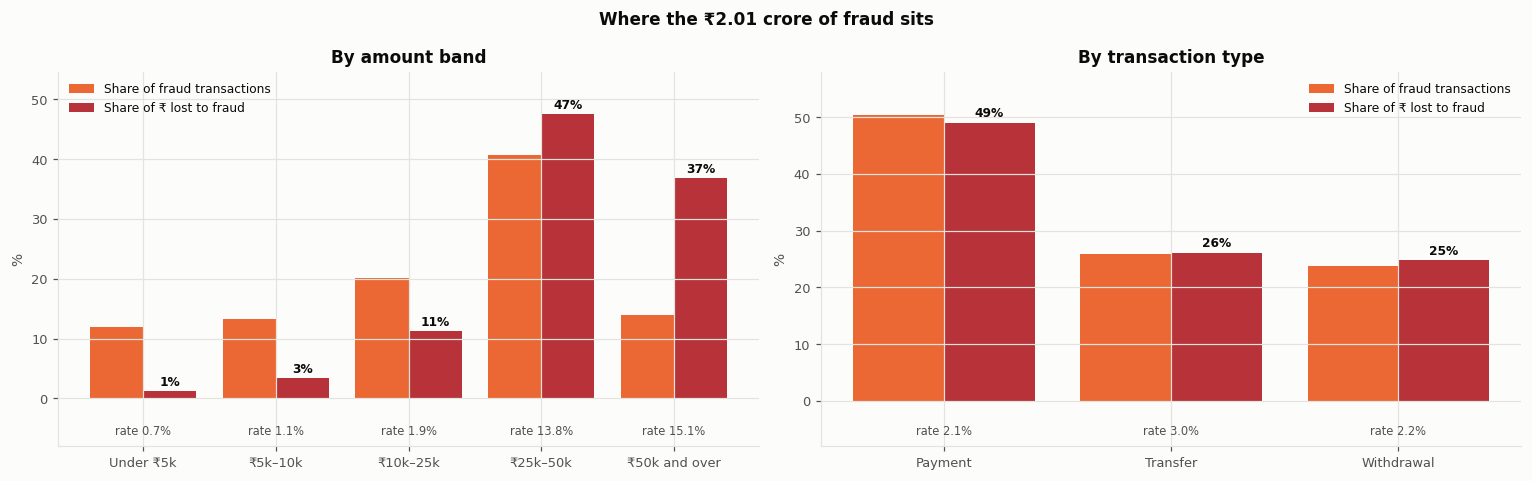

,Transactions,Frauds,Fraud rate,95% low,95% high,Share of frauds,₹ in fraud (lakh),Share of fraud ₹,Average amount (₹)
Amount,,,,,,,,,
Under ₹5k,"11,789",82,0.70%,0.56%,0.86%,12.0%,₹2.4,1.2%,"₹2,793"
₹5k–10k,"8,168",91,1.11%,0.91%,1.37%,13.3%,₹6.7,3.3%,"₹7,184"
₹10k–25k,"7,406",138,1.86%,1.58%,2.20%,20.2%,₹22.5,11.2%,"₹15,401"
₹25k–50k,"2,008",278,13.84%,12.40%,15.42%,40.6%,₹95.4,47.5%,"₹33,794"
₹50k and over,629,95,15.10%,12.52%,18.11%,13.9%,₹73.9,36.8%,"₹78,407"


In [19]:
bands = pd.cut(tx.Amount, [0, 5_000, 10_000, 25_000, 50_000, np.inf],
               labels=["Under ₹5k", "₹5k–10k", "₹10k–25k", "₹25k–50k", "₹50k and over"])
board_amt = fraud_by(tx, bands)
board_type = fraud_by(tx, tx.Transaction_Type)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
for ax, tbl, title in [(axes[0], board_amt, "By amount band"), (axes[1], board_type, "By transaction type")]:
    x = np.arange(len(tbl))
    ax.bar(x - 0.2, tbl["Share of frauds"] * 100, 0.4, color=ORANGE, label="Share of fraud transactions")
    ax.bar(x + 0.2, tbl["Share of fraud ₹"] * 100, 0.4, color=FRAUD, label="Share of ₹ lost to fraud")
    for i, (a, b, rt) in enumerate(zip(tbl["Share of frauds"], tbl["Share of fraud ₹"], tbl["Fraud rate"])):
        ax.text(i + 0.2, b * 100 + 1, f"{b:.0%}", ha="center", fontsize=8, fontweight="bold")
        ax.text(i, -6, f"rate {rt:.1%}", ha="center", fontsize=7.5, color=INK_2)
    ax.set_xticks(x, tbl.index, fontsize=8.5); ax.set_ylim(-8, max(tbl["Share of fraud ₹"].max(), tbl["Share of frauds"].max()) * 115)
    ax.set_ylabel("%"); ax.set_title(title); ax.legend(frameon=False, fontsize=8)
fig.suptitle(f"Where the ₹{tx.Amount[fraud].sum() / CRORE:.2f} crore of fraud sits", fontsize=11, fontweight="bold")
fig.tight_layout(); save_chart(fig, "07_board_view"); plt.show()
show(board_amt)

## 12. What the results say

### The data (step 1)
- 30,000 transactions from 2,500 customers (about 12 each), January 2025 to August 2026. No missing values, duplicates or impossible amounts.
- **About 49 transactions a day.** The brief says "thousands every day", so this file is a sample. Daily volumes in later tasks are scaled from it and say so.
- **The "customer" columns describe the transaction, not a fixed customer.** For every customer, Historical_Avg_Transaction, Account_Age_Months and Transaction_Frequency take a different value on almost every transaction. Device_ID behaves like a random label: 1,500 devices, each used by about 20 different customers, and a customer's device changes on 99.95% of their transactions.

### Fraud rate (step 2)

| Measure | Value |
| --- | --- |
| Fraud transactions | **684 of 30,000 = 2.28%** (95% range 2.12–2.46%) |
| ₹ lost to fraud | **₹2.01 crore of ₹32.28 crore = 6.2% of the money** |
| Average fraud / normal transaction | ₹29,380 / ₹10,327 |
| Median fraud / normal transaction | ₹26,438 / ₹6,411 |

- **Fraud is rare by count but large by money:** 2.3% of transactions, 6.2% of the ₹, because frauds are about three to four times bigger than normal transactions.
- **The rate is stable over time:** months don't differ (p = 0.65), and there is no steady rise or fall (p = 0.87). A model trained on earlier months should suit later ones.

### The evidence table: every column on the same yardsticks (step 10)

16 tests, so the Bonferroni line is p < 0.0031.

| Column | Fraud rate, lowest → highest group | p | ROC-AUC | Verdict |
| --- | --- | --- | --- | --- |
| **Amount** | 0.6% → 12.7% (tenths) | < 10⁻³⁰ | **0.788** | **Strong** |
| **Amount ÷ usual amount** | 0.5% → 10.3% | < 10⁻³⁰ | **0.787** | **Strong** |
| Usual transaction size (Historical_Avg) | 3.3% → 1.1% (smaller usual size, more fraud) | 5 × 10⁻⁹ | 0.583 | Weak |
| Transaction type | 2.1% (Payment) → 3.0% (Transfer) | 0.0003 | 0.533 | Weak |
| Merchant category | 2.0% → 2.5% | 0.43 | 0.526 | Not informative |
| Hour of day | 2.0% → 2.6% | 0.33 | 0.526 | Not informative |
| Account age | 1.6% → 2.8% | 0.16 | 0.519 | Not informative |
| Day of week | 2.0% → 2.4% | 0.82 | 0.518 | Not informative |
| Transaction frequency | 2.0% → 2.7% | 0.29 | 0.517 | Not informative |
| Location (city) | 2.1% → 2.4% | 0.96 | 0.513 | Not informative |
| Device had an earlier fraud | 2.2% vs 2.5% | 0.31 | 0.508 | Not informative |
| Location change since the last transaction | 2.2% vs 2.4% | 0.49 | 0.505 | Not informative |
| Customer had an earlier fraud | 2.2% vs 2.3% | 0.71 | 0.503 | Not informative |
| Device change since the last transaction | changes on 99.95%; the 14 without a change are too few to compare | 0.74 | 0.501 | Not informative |
| Frauds cluster on devices | 0–4 frauds per device, close to chance | 0.046 | — | Not informative (Weak at a plain 0.05) |
| Frauds cluster on customers | 0–3 frauds per customer, as chance predicts | 0.61 | — | Not informative |

**Checks on the rule itself:**
- **The 0.60 line decides nothing:** the two strong columns score 0.79 and the next best 0.58, so any line from 0.59 to 0.78 gives the same verdicts.
- **The Bonferroni adjustment changes one verdict:** device clustering (p = 0.046) would be "Weak" at a plain 0.05. Even so, a transaction on a device with an earlier fraud is no riskier (2.5% vs 2.2%, p = 0.31), so there is no usable device signal.

### What this means, brief item by brief item
- **Fraud by amount: the dominant signal.** Fraud rises from 0.6% in the smallest tenth to 12.7% in the largest. The largest 10% of transactions (₹23,331 and over) hold **56% of all frauds and 85% of the ₹ lost**.
- **Fraud by customer behaviour: what matters is the amount against the customer's usual one.** A typical fraud is 5.0× the customer's usual amount; a normal transaction 1.2×. Fraud is also a little more common among customers whose usual amount is small (3.3% vs 1.1%). This works through the jump: amount and usual amount are unrelated (correlation 0.00), and for the same amount a smaller usual amount still raises the risk (a two-input logistic check, both p < 0.001). Account age and transaction frequency make no difference.
- **Fraud by transaction type: a small real effect.** Transfers are fraud 3.0% of the time, against 2.1–2.2% for payments and withdrawals (p = 0.0001 for Transfer against the rest). It is real, but too small to pick out fraud on its own (ROC-AUC 0.53).
- **Fraud by location: no effect.** Every city sits at 2.1–2.4%, inside each other's 95% ranges (p = 0.96).
- **Also no effect:** merchant category, time of day, day of week, device and location changes, and any device or customer history.
- **Amount and the amount ratio overlap heavily** (correlation 0.71). Task 2 decides whether the model needs both.

### Two kinds of fraud (steps 4 and 11)

| Amount band | Fraud rate | Share of frauds | Share of ₹ lost |
| --- | --- | --- | --- |
| Under ₹5k | 0.7% | 12% | 1% |
| ₹5k–10k | 1.1% | 13% | 3% |
| ₹10k–25k | 1.9% | 20% | 11% |
| ₹25k–50k | **13.8%** | 41% | **47%** |
| ₹50k and over | **15.1%** | 14% | **37%** |

- **Large frauds:** transactions of ₹25,000 and over are 9% of transactions but hold **55% of frauds and 84% of the ₹ lost**, at a fraud rate of about 14%. These stand out by size.
- **Ordinary-looking frauds:** a third of frauds sit at ordinary amounts (under about ₹15,000). In this data nothing else marks them out. They carry only about 8% of the ₹ lost.
- **What this sets up for Tasks 2–4:** any model should catch the large frauds well and the ordinary-looking ones poorly. Missing an ordinary-looking fraud costs far less in ₹ than missing a large one, but the brief's Task 4 counts every missed fraud at the same ₹10,000. That is weighed at Task 4.

### What goes to Task 2
- `outputs/task1/FINAL_M3_T1_fraud_evidence.csv`: every column's evidence and verdict.
- **For Task 2 to decide, with this evidence:**
  - which columns to feed the models (two strong, two weak, the rest not informative on their own);
  - whether to keep both Amount and the amount ratio;
  - how to split training and test data. Fraud is stable over time, so a time split and a random split should give similar results; Task 2 tests that.

## 13. Save the outputs

Only files someone outside this notebook uses are saved (decision M3-16); every other table is shown above and in the report.
- `FINAL_M3_T1_fraud_evidence.csv`: every column's test, ROC-AUC and verdict (used by Task 2 when the model inputs were agreed).
- The charts above, and `key_numbers.json` with the headline numbers of this run.

In [20]:
def r4(v):
    return round(float(v), 4)


key = {
    "transactions": len(tx), "frauds": int(fraud.sum()), "fraud_rate": r4(FRAUD_RATE),
    "fraud_crore": round(float(tx.Amount[fraud].sum() / CRORE), 2),
    "fraud_rate_by_money": r4(overall["Fraud rate by money"]),
    "average_fraud": round(float(tx.Amount[fraud].mean()), 0), "median_fraud": round(float(tx.Amount[fraud].median()), 0),
    "median_normal": round(float(tx.Amount[~fraud].median()), 0),
    "month_p": r4(p_month), "n_tests": N_TESTS, "p_line": r4(P_LINE),
    "verdicts": dict(zip(ev.Column, ev.Verdict)),
    "roc_auc": {c: r4(a) for c, a in zip(ev.Column, ev["ROC-AUC"]) if not np.isnan(a)},
    "top10_share_frauds": r4(conc.loc[conc["Largest transactions"] == "10%", "Share of all frauds"].iloc[0]),
    "top10_share_fraud_rupees": r4(conc.loc[conc["Largest transactions"] == "10%", "Share of fraud ₹"].iloc[0]),
}
(OUT_DIR / "key_numbers.json").write_text(json.dumps(key, indent=1, ensure_ascii=False), encoding="utf-8")
print("Saved to", OUT_DIR.relative_to(PROJECT_ROOT).as_posix())
print(sorted(p.name for p in OUT_DIR.iterdir()))

Saved to module_03_fraud_detection/outputs/task1
['01_fraud_rate_by_month.png', '02_fraud_by_amount.png', '03_fraud_by_type_city_merchant.png', '04_fraud_by_customer_behaviour.png', '05_fraud_by_time.png', '06_evidence_table.png', '07_board_view.png', 'FINAL_M3_T1_fraud_evidence.csv', 'key_numbers.json']
